# Cavità, Q-switching e mode-locking

### Subject: Quantum electronics

Il recap in `03_course_recap.ipynb` copre Rabi, rate equations, semiconduttori,
fotoni in un cristallo, SPP e quantum dots. Manca il pezzo da **cavità** a
**impulso**: Fabry–Pérot, vita media del fotone, Q-switch, mode-locking.
Qui lo riempiamo con note originali e demo numeriche.

Le slide del corso restano in `data/` (non pubblicate).

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
print("Setup ready.")

Setup ready.


## 1. Fabry–Pérot: un filtro che è già un risonatore

Due specchi paralleli, riflettività $R$, spessore ottico $L'$. La trasmissione
è la **funzione di Airy**:

$$
T(\varphi) = \frac{(1-R)^2}{\bigl(1-R\bigr)^2 + 4R\sin^2\varphi},
\qquad \varphi = \frac{2\pi\nu L'}{c}.
$$

I massimi cadono a $\nu_m = m\,c/(2L')$. La distanza tra due massimi è il
**free spectral range** $\Delta\nu_\mathrm{FSR}=c/(2L')$. Il rapporto FSR / larghezza
del picco è la **finesse**

$$
F = \frac{\pi\sqrt{R}}{1-R}.
$$

Alta $R$ → picchi stretti → il Fabry–Pérot è uno spettrometro, e la stessa
geometria è la cavità di un laser.

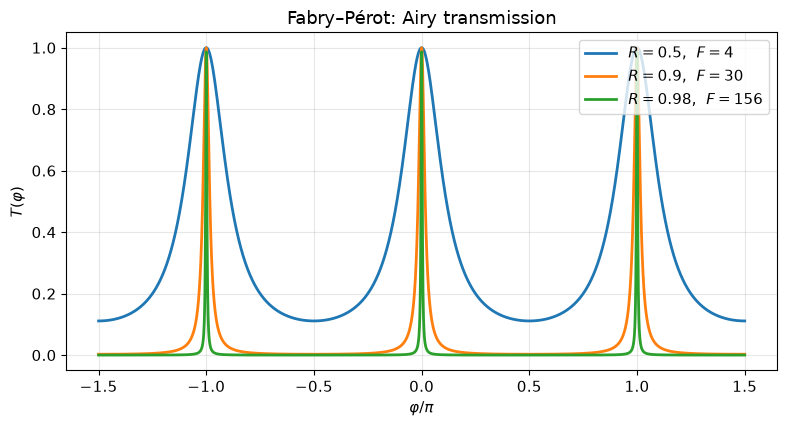

R=0.98 → F ≈ 155.5  (peaks ~150 times narrower than the FSR)


In [2]:
def airy_T(phi, R):
    return (1 - R) ** 2 / ((1 - R) ** 2 + 4 * R * np.sin(phi) ** 2)

def finesse(R):
    return np.pi * np.sqrt(R) / (1 - R)

phi = np.linspace(-1.5 * np.pi, 1.5 * np.pi, 4000)
fig, ax = plt.subplots()
for R in (0.5, 0.9, 0.98):
    ax.plot(phi / np.pi, airy_T(phi, R), lw=2, label=fr"$R={R}$,  $F={finesse(R):.0f}$")
ax.set_xlabel(r"$\varphi / \pi$")
ax.set_ylabel(r"$T(\varphi)$")
ax.set_title("Fabry–Pérot: Airy transmission")
ax.legend()
plt.tight_layout()
plt.show()
print(f"R=0.98 → F ≈ {finesse(0.98):.1f}  (peaks ~150 times narrower than the FSR)")

## 2. Vita media del fotone e fattore $Q$

Dopo un round-trip la frazione di luce rimasta è $R_1 R_2(1-T_i)^2$. In continuo:

$$
q(t)=q_0 e^{-t/\tau_c},\qquad
\tau_c = -\frac{2L}{c\,\ln\bigl[R_1 R_2(1-T_i)^2\bigr]}.
$$

Lo spettro del campo decadente è una lorentziana di larghezza
$\Delta\nu_c = 1/(2\pi\tau_c)$. Il **fattore di merito** è $Q=\nu/\Delta\nu_c=2\pi\nu\tau_c$.
Q alto = poche perdite = soglia laser più bassa.

In [3]:
c = 2.998e8
L, R, T_i = 0.90, 0.98, 0.0
tau_c = -2 * L / (c * np.log(R * R * (1 - T_i) ** 2))
dnu_c = 1.0 / (2 * np.pi * tau_c)
nu = c / 0.6e-6
Q = nu / dnu_c
print(f"L={L:.2f} m, R={R:.2f}")
print(f"τ_c  = {tau_c*1e9:.1f} ns")
print(f"Δν_c = {dnu_c/1e6:.2f} MHz")
print(f"Q    = {Q:.2e}   (at λ=0.6 µm)")

L=0.90 m, R=0.98
τ_c  = 148.6 ns
Δν_c = 1.07 MHz
Q    = 4.67e+08   (at λ=0.6 µm)


## 3. Q-switching: accumulare inversione, poi aprire la cavità

Idea: tenere $Q$ basso mentre la pompa carica l'inversione $N_i$, poi alzare $Q$
di colpo. L'energia esce in un impulso corto e intenso.

Dopo lo switch (si trascurano pompa e decadimento spontaneo):

$$
\dot N = -B q N, \qquad \dot q = (V_a B N - 1/\tau_c)\,q.
$$

Il picco cade a $N_p=1/(V_a B \tau_c)$. Per $N_i/N_p\approx 2.5$ la durata è
$\Delta\tau_p\approx 3\tau_c$. **Attivo** = shutter comandato (Pockels, AO);
**passivo** = assorbitore saturabile.

N_i/N_p = 2.50
peak at t/τ_c = 7.02,  q_max = 0.584
rule of thumb Δτ_p ≈ 3 τ_c  (pulse sits on a few cavity lifetimes)


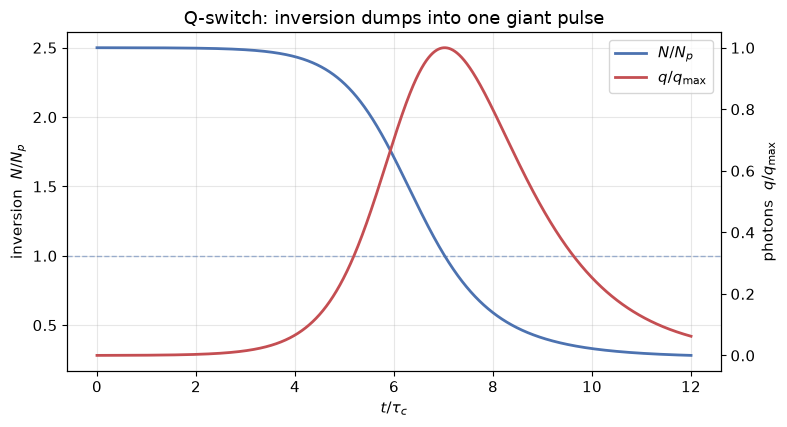

In [4]:
def rk4(fun, y0, t):
    y = np.empty((len(t), len(y0)))
    y[0] = y0
    for i in range(len(t) - 1):
        dt = t[i + 1] - t[i]
        k1 = fun(y[i])
        k2 = fun(y[i] + 0.5 * dt * k1)
        k3 = fun(y[i] + 0.5 * dt * k2)
        k4 = fun(y[i] + dt * k3)
        y[i + 1] = y[i] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

tau_c, B, Va = 1.0, 1.0, 1.0
Np = 1.0 / (Va * B * tau_c)
Ni = 2.5 * Np

def rhs(y):
    N, q = y
    return np.array([-B * q * N, (Va * B * N - 1.0 / tau_c) * q])

t = np.linspace(0.0, 12.0, 4000)
traj = rk4(rhs, np.array([Ni, 1e-4]), t)
N, q = traj[:, 0], traj[:, 1]
t_peak = t[np.argmax(q)]
print(f"N_i/N_p = {Ni/Np:.2f}")
print(f"peak at t/τ_c = {t_peak:.2f},  q_max = {q.max():.3f}")
print(f"rule of thumb Δτ_p ≈ 3 τ_c  (pulse sits on a few cavity lifetimes)")

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(t, N / Np, color="#4C72B0", lw=2, label=r"$N/N_p$")
ax2.plot(t, q / q.max(), color="#C44E52", lw=2, label=r"$q/q_\mathrm{max}$")
ax1.axhline(1.0, color="#4C72B0", ls="--", lw=1, alpha=0.5)
ax1.set_xlabel(r"$t / \tau_c$")
ax1.set_ylabel(r"inversion  $N/N_p$")
ax2.set_ylabel(r"photons  $q/q_\mathrm{max}$")
ax1.set_title("Q-switch: inversion dumps into one giant pulse")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
ax2.grid(False)
plt.tight_layout()
plt.show()

## 4. Mode-locking: agganciate le fasi, esce un treno di impulsi

Un laser multimodo con fasi casuali dà un'uscita irregolare. Se
$\varphi_k-\varphi_{k-1}=\alpha$ costante, $2N+1$ modi di ampiezza uguale
interferiscono:

$$
A(t) = E_0\,\frac{\sin\bigl[(2N+1)(\omega t+\alpha)/2\bigr]}{\sin\bigl[(\omega t+\alpha)/2\bigr]}.
$$

- distanza tra impulsi: $\tau=2d/c$ (round-trip);
- durata: $\Delta\tau_p\approx 1/\Delta\nu$ (banda totale);
- picco $\propto (2N+1)^2$ invece di $2N+1$.

Attivo: si modulano le perdite a $\omega'=\pi c/d$. Passivo: assorbitore
saturabile (o Kerr-lens nel Ti:zaffiro).

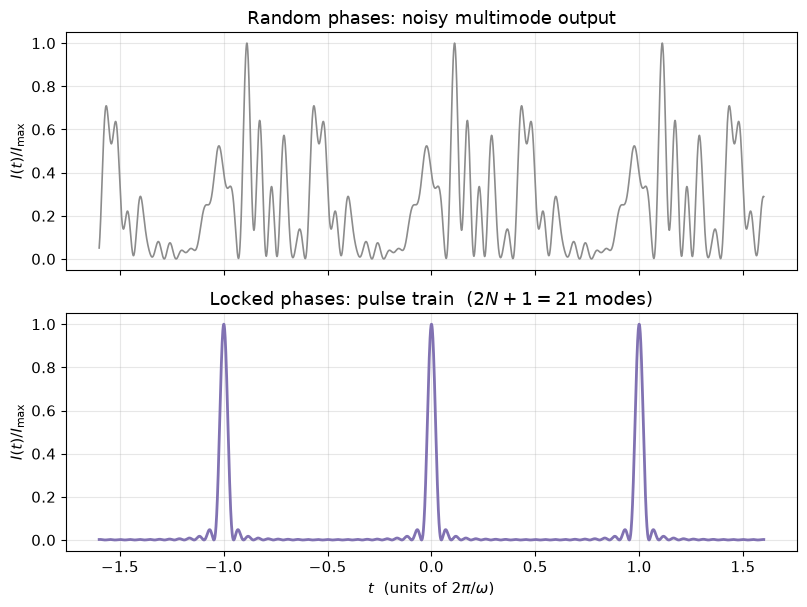

peak ratio locked/random (this draw) = 1.00 after normalisation
Before normalisation the locked peak scales as (2N+1)^2 vs (2N+1) for random phases.


In [5]:
def locked_envelope(t, n_modes, omega):
    N = (n_modes - 1) // 2
    arg = 0.5 * omega * t
    return np.sin((2 * N + 1) * arg) / np.sin(np.where(np.abs(arg) < 1e-12, 1e-12, arg))

rng = np.random.default_rng(0)
n_modes, omega = 21, 2 * np.pi
t = np.linspace(-1.6, 1.6, 4000)
A_lock = locked_envelope(t, n_modes, omega)
I_lock = A_lock ** 2
I_lock /= I_lock.max()

phases = rng.uniform(0, 2 * np.pi, n_modes)
l = np.arange(-(n_modes // 2), n_modes // 2 + 1)
field = np.exp(1j * (np.outer(l, omega * t).T + phases))
I_rand = np.abs(field.sum(axis=1)) ** 2
I_rand /= I_rand.max()

fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)
axes[0].plot(t, I_rand, color="#8C8C8C", lw=1.2)
axes[0].set_title("Random phases: noisy multimode output")
axes[0].set_ylabel(r"$I(t)/I_\mathrm{max}$")
axes[1].plot(t, I_lock, color="#8172B2", lw=2)
axes[1].set_title(fr"Locked phases: pulse train  ($2N+1={n_modes}$ modes)")
axes[1].set_xlabel(r"$t$  (units of $2\pi/\omega$)")
axes[1].set_ylabel(r"$I(t)/I_\mathrm{max}$")
plt.tight_layout()
plt.show()
print(f"peak ratio locked/random (this draw) = {I_lock.max()/I_rand.max():.2f} after normalisation")
print("Before normalisation the locked peak scales as (2N+1)^2 vs (2N+1) for random phases.")

## Cosa ricordare

- Fabry–Pérot = Airy + FSR + finesse: è il prototipo della cavità laser.
- $\tau_c$ fissa $\Delta\nu_c$ e $Q$; Q alto abbassa la soglia.
- Q-switch: inversione accumulata → un impulso; $\Delta\tau_p$ è poche $\tau_c$.
- Mode-locking: fasi agganciate → treno con periodo $2d/c$ e durata $1/\Delta\nu$.

Collegamenti: `03_course_recap.ipynb` (rate equations, SPP), `07_nonlinear_optics/`
(Kerr-lens vive di $n_2$).